# Tugas UTS: Linear Regression & Logistic Regression

**Mata Kuliah:** Machine Learning

**Identitas Mahasiswa**

- Nama : Valentina Nelu
- NIM : 241011400687
- Kelas : Reg B

## Persiapan

Library yang dipakai hanya `numpy`, `pandas`, dan `matplotlib`. Model dan metrik evaluasi diimplementasikan sendiri dengan NumPy (scikit-learn hanya dipakai di soal Bonus).
`RANDOM_STATE` diisi dengan 2 digit terakhir NIM, yaitu **87**.

In [1]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 87   # 2 digit terakhir NIM

In [2]:
# Fungsi train_test_split (implementasi sendiri, seperti di materi)
def train_test_split(X, y, test_size=0.2, random_state=None):
    rng = np.random.RandomState(random_state)   # pengacak dengan seed tetap
    n = len(X)
    idx = rng.permutation(n)                     # acak urutan indeks data
    n_test = int(round(n * test_size))           # jumlah data testing
    test_idx, train_idx = idx[:n_test], idx[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

In [3]:
# Model Regresi Linear (Normal Equation): theta = (X^T X)^-1 X^T y
class LinearRegression:
    def fit(self, X, y):
        Xb = np.c_[np.ones(len(X)), X]                      # tambah kolom 1 untuk intercept
        theta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y       # rumus normal equation
        self.intercept_, self.coef_ = theta[0], theta[1:]
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_


# Model Regresi Linear (Gradient Descent) dengan loss MSE
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iter = n_iterations

    def fit(self, X, y):
        n = len(X)
        self.intercept_, self.coef_ = 0.0, np.zeros(X.shape[1])
        self.loss_history_ = []
        for _ in range(self.n_iter):
            y_hat = self.intercept_ + X @ self.coef_
            error = y_hat - y
            self.loss_history_.append(np.mean(error ** 2))          # catat MSE tiap iterasi
            self.intercept_ -= self.lr * (2 / n) * error.sum()      # turunan MSE terhadap b
            self.coef_ -= self.lr * (2 / n) * (X.T @ error)         # turunan MSE terhadap m
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_


# Fungsi sigmoid dan model Logistic Regression (Gradient Descent) dengan loss log loss
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.lr = learning_rate
        self.n_iter = n_iterations

    def fit(self, X, y):
        n = len(X)
        self.intercept_, self.coef_ = 0.0, np.zeros(X.shape[1])
        self.loss_history_ = []
        eps = 1e-15                                                  # cegah log(0)
        for _ in range(self.n_iter):
            p = sigmoid(self.intercept_ + X @ self.coef_)
            p_clip = np.clip(p, eps, 1 - eps)
            self.loss_history_.append(-np.mean(y * np.log(p_clip) + (1 - y) * np.log(1 - p_clip)))
            error = p - y
            self.intercept_ -= self.lr * error.mean()
            self.coef_ -= self.lr * (X.T @ error) / n
        return self

    def predict_proba(self, X):
        return sigmoid(self.intercept_ + X @ self.coef_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

In [4]:
# Metrik klasifikasi dari materi (accuracy & confusion matrix) + metrik tambahan
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    # hasil: [[TN, FP], [FN, TP]]
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Dataset: `Ads_Data.csv`.

## Soal A1 – Load & Visualisasi Data

1. Baca `Ads_Data.csv` dengan pandas, tampilkan 5 data pertama dan jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat scatter plot `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

Jumlah baris data: 40


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Shape X: (40, 1) | Shape y: (40,)


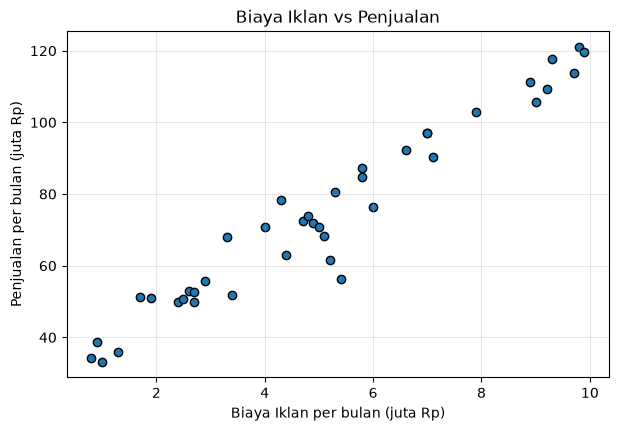

In [5]:
# Jawaban A1
df_ads = pd.read_csv("Ads_Data.csv")
print("Jumlah baris data:", len(df_ads))
display(df_ads.head())

X = df_ads[["BiayaIklan"]].values      # 2 dimensi -> (n, 1)
y = df_ads["Penjualan"].values         # 1 dimensi -> (n,)
print("Shape X:", X.shape, "| Shape y:", y.shape)

plt.figure(figsize=(7, 4.5))
plt.scatter(X, y, color="tab:blue", edgecolor="k")
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan per bulan (juta Rp)")
plt.ylabel("Penjualan per bulan (juta Rp)")
plt.grid(alpha=0.3)
plt.show()

**Jawaban A1 (pengamatan):** Dataset berisi 40 baris. Titik-titik membentuk pola naik dari kiri bawah ke kanan atas, artinya makin besar biaya iklan, penjualan cenderung makin tinggi. Hubungannya mendekati garis lurus, sehingga model regresi linear masuk akal dipakai.

## Soal A2 – Split Data

Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [6]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


## Soal A3 – Training dengan Normal Equation

1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini.

In [7]:
# Jawaban A3
model_ne = LinearRegression()
model_ne.fit(X_train, y_train)

b_ne = model_ne.intercept_
m_ne = model_ne.coef_[0]
print(f"Intercept (b) : {b_ne:.4f}")
print(f"Koefisien (m) : {m_ne:.4f}")
print(f"Persamaan     : y_hat = {b_ne:.4f} + {m_ne:.4f} * BiayaIklan")

Intercept (b) : 28.1481
Koefisien (m) : 9.2856
Persamaan     : y_hat = 28.1481 + 9.2856 * BiayaIklan


**Jawaban A3 (interpretasi):**

Persamaan garis regresi: $\hat{y} = 28{,}1481 + 9{,}2856\,X$.

Nilai $m = 9{,}29$ berarti **setiap kenaikan biaya iklan Rp1 juta, penjualan per bulan naik sekitar Rp9,29 juta**. Nilai $b = 28{,}15$ adalah perkiraan penjualan dasar (Rp28,15 juta) ketika biaya iklan 0; ini hanya perkiraan matematis karena data terkecil kita dimulai dari biaya iklan 0,8 juta.

## Soal A4 – Evaluasi Model

Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad RMSE = \sqrt{MSE}$$

$$R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [8]:
# Jawaban A4
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)            # jumlah kuadrat residual
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)   # jumlah kuadrat total
    return 1 - ss_res / ss_tot

pred_train = model_ne.predict(X_train)
pred_test = model_ne.predict(X_test)

hasil_a4 = pd.DataFrame({
    "MAE":  [mae(y_train, pred_train),  mae(y_test, pred_test)],
    "MSE":  [mse(y_train, pred_train),  mse(y_test, pred_test)],
    "RMSE": [rmse(y_train, pred_train), rmse(y_test, pred_test)],
    "R2":   [r2_score(y_train, pred_train), r2_score(y_test, pred_test)],
}, index=["Training", "Testing"]).round(4)
display(hasil_a4)
print("Rata-rata penjualan:", round(y.mean(), 2), "| Std penjualan:", round(y.std(), 2))

,MAE,MSE,RMSE,R2
Training,4.0245,27.9056,5.2826,0.9473
Testing,5.9217,72.8966,8.5380,0.9196


Rata-rata penjualan: 74.27 | Std penjualan: 25.19


**Jawaban A4 (analisis):**

- **RMSE** training = 5,28 dan testing = 8,54 (satuan juta Rp). Artinya rata-rata prediksi pada data testing meleset sekitar Rp8,5 juta dari penjualan sebenarnya. Dibanding rata-rata penjualan (sekitar 74,3 juta) kesalahan itu masih kecil, sekitar 11,5% (RMSE testing dibagi rata-rata penjualan).
- **$R^2$** training = 0,947 dan testing = 0,920, yaitu sekitar 92–95% variasi penjualan dapat dijelaskan oleh biaya iklan.
- Nilai testing sedikit lebih buruk daripada training (RMSE 8,54 vs 5,28), hal yang wajar karena model dilatih pada data training. Data testing hanya 8 baris, sehingga satu atau dua titik yang agak jauh dari garis sudah cukup menaikkan MSE.
- **Kesimpulan:** model sudah **cukup baik** untuk data ini, karena $R^2$ tinggi (di atas 0,9) pada training maupun testing dan RMSE relatif kecil. Selisih training dan testing ada tetapi kecil, sehingga tidak ada tanda overfitting yang serius.

## Soal A5 – Gradient Descent & Learning Rate

1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.

C:\Users\User\AppData\Local\Temp\ipykernel_12700\1936790075.py:26: RuntimeWarning: overflow encountered in square
  self.loss_history_.append(np.mean(error ** 2))          # catat MSE tiap iterasi
c:\Users\User\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\User\AppData\Local\Temp\ipykernel_12700\1936790075.py:28: RuntimeWarning: overflow encountered in matmul
  self.coef_ -= self.lr * (2 / n) * (X.T @ error)         # turunan MSE terhadap m
C:\Users\User\AppData\Local\Temp\ipykernel_12700\1936790075.py:28: RuntimeWarning: invalid value encountered in subtract
  self.coef_ -= self.lr * (2 / n) * (X.T @ error)         # turunan MSE terhadap m


,Metode,Intercept (b),Koefisien (m),MSE akhir (train)
0,Normal Equation,28.1481,9.2856,27.9056
1,GD lr=0.001,23.3735,10.0395,31.8705
2,GD lr=0.02,28.1481,9.2856,27.9056
3,GD lr=0.1,NaN,NaN,NaN


Learning rate 0.1: loss pertama kali inf/NaN pada iterasi ke- 199
Loss lr=0.1 pada iterasi 1, 10, 50, 100: ['6.456e+03', '4.215e+17', '1.169e+79', '7.441e+155']
Batas learning rate stabil kira-kira: 0.0291


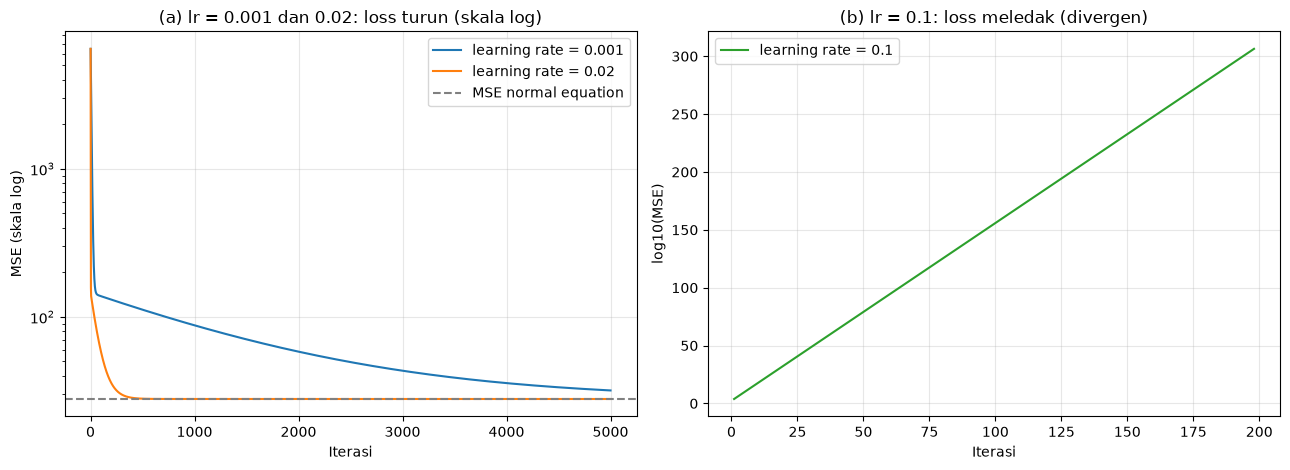

In [9]:
# Jawaban A5
learning_rates = [0.001, 0.02, 0.1]
model_gd = {}
for lr in learning_rates:
    model_gd[lr] = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)

# Tabel perbandingan intercept & koefisien
baris = [{"Metode": "Normal Equation", "Intercept (b)": b_ne, "Koefisien (m)": m_ne,
          "MSE akhir (train)": mse(y_train, pred_train)}]
for lr, mdl in model_gd.items():
    baris.append({"Metode": f"GD lr={lr}", "Intercept (b)": mdl.intercept_, "Koefisien (m)": mdl.coef_[0],
                  "MSE akhir (train)": mdl.loss_history_[-1]})
display(pd.DataFrame(baris).round(4))

# Iterasi pertama saat loss menjadi tak terhingga / NaN (overflow)
loss_01 = np.array(model_gd[0.1].loss_history_)
iter_gagal = np.where(~np.isfinite(loss_01))[0][0] + 1
print("Learning rate 0.1: loss pertama kali inf/NaN pada iterasi ke-", iter_gagal)
print("Loss lr=0.1 pada iterasi 1, 10, 50, 100:", [f"{loss_01[i-1]:.3e}" for i in (1, 10, 50, 100)])

# Batas learning rate yang masih stabil: lr < 2 / lambda_max(Hessian)
Xb = np.c_[np.ones(len(X_train)), X_train]
H = (2 / len(X_train)) * Xb.T @ Xb
print("Batas learning rate stabil kira-kira:", round(2 / np.max(np.linalg.eigvalsh(H)), 4))

# Grafik loss vs iterasi
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))

# (a) lr yang tidak meledak, skala log
for lr in [0.001, 0.02]:
    ax[0].plot(range(1, 5001), model_gd[lr].loss_history_, label=f"learning rate = {lr}")
ax[0].axhline(mse(y_train, pred_train), color="gray", linestyle="--", label="MSE normal equation")
ax[0].set_yscale("log")
ax[0].set_title("(a) lr = 0.001 dan 0.02: loss turun (skala log)")
ax[0].set_xlabel("Iterasi")
ax[0].set_ylabel("MSE (skala log)")
ax[0].legend()
ax[0].grid(alpha=0.3)

# (b) lr = 0.1: loss meledak, ditampilkan sebagai log10(MSE) sampai sebelum inf/NaN
loss_valid = loss_01[np.isfinite(loss_01)]
ax[1].plot(range(1, len(loss_valid) + 1), np.log10(loss_valid), color="tab:green", label="learning rate = 0.1")
ax[1].set_title("(b) lr = 0.1: loss meledak (divergen)")
ax[1].set_xlabel("Iterasi")
ax[1].set_ylabel("log10(MSE)")
ax[1].legend()
ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):**

- **lr = 0,001 (terlalu lambat):** setelah 5000 iterasi hasilnya belum sampai. Intercept = 23,37 dan koefisien = 10,04, padahal normal equation 28,15 dan 9,29. MSE akhir 31,87, masih di atas 27,91 dan grafiknya masih menurun. Langkahnya terlalu kecil sehingga butuh iterasi jauh lebih banyak.
- **lr = 0,02 (pas):** konvergen ke intercept 28,1481 dan koefisien 9,2856, **sama dengan normal equation**. MSE turun cepat dan sudah hampir mendatar sebelum iterasi ke-1000 (27,9057), berakhir di 27,9056. Langkahnya cukup besar tapi masih aman.
- **lr = 0,1 (divergen):** loss tidak turun, malah membesar: sekitar $10^{17}$ pada iterasi ke-10 dan $10^{155}$ pada iterasi ke-100, lalu menjadi `inf`/`NaN` mulai iterasi ke-199 sehingga intercept dan koefisien akhirnya `NaN`. Langkah terlalu besar membuat parameter melompati titik minimum ke sisi seberang, dan lompatan berikutnya lebih jauh lagi. Batas learning rate yang aman untuk data ini hanya sekitar 0,03 (lihat output), jadi 0,1 sudah di luar batas.
- **`RuntimeWarning: overflow`** artinya angka hasil hitung sudah melebihi batas terbesar yang bisa disimpan komputer (float64, sekitar $10^{308}$). Ini bukti bahwa gradient descent meledak, bukan kesalahan kode.

## Soal A6 – Visualisasi & Prediksi

1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

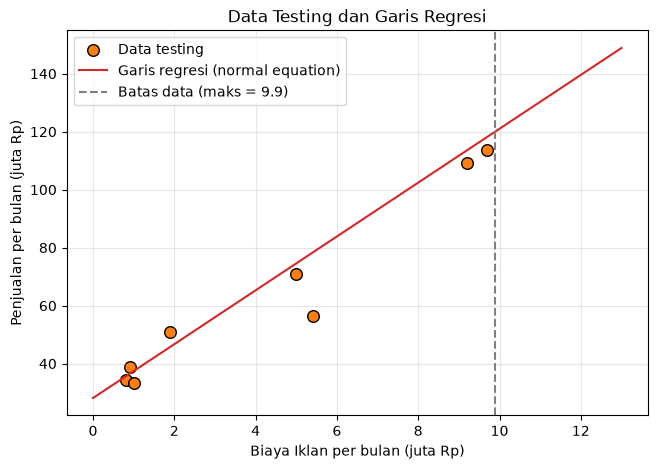

,Biaya Iklan (juta),Prediksi Penjualan (juta)
0,4.5,69.93
1,7.0,93.15
2,12.0,139.57


Rentang BiayaIklan pada data: 0.8 sampai 9.9


In [10]:
# Jawaban A6
# 1. Scatter data testing + garis regresi
x_garis = np.linspace(0, 13, 100).reshape(-1, 1)
plt.figure(figsize=(7.5, 5))
plt.scatter(X_test, y_test, color="tab:orange", edgecolor="k", s=70, label="Data testing")
plt.plot(x_garis, model_ne.predict(x_garis), color="tab:red", label="Garis regresi (normal equation)")
plt.axvline(X.max(), color="gray", linestyle="--", label="Batas data (maks = %.1f)" % X.max())
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan per bulan (juta Rp)")
plt.ylabel("Penjualan per bulan (juta Rp)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 2. Prediksi untuk biaya iklan baru
biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi = model_ne.predict(biaya_baru)
display(pd.DataFrame({"Biaya Iklan (juta)": biaya_baru.ravel(),
                      "Prediksi Penjualan (juta)": prediksi.round(2)}))
print("Rentang BiayaIklan pada data: %.1f sampai %.1f" % (X.min(), X.max()))

**Jawaban A6 (analisis):**

Prediksi penjualan: biaya iklan 4,5 juta menghasilkan sekitar **69,93 juta**, 7 juta menghasilkan **93,15 juta**, dan 12 juta menghasilkan **139,57 juta**.

Prediksi 4,5 dan 7 juta cukup bisa dipercaya karena berada **di dalam rentang data** (0,8 sampai 9,9 juta) tempat model dilatih. Prediksi 12 juta adalah **ekstrapolasi**: model hanya mengasumsikan garis lurus terus berlanjut, padahal kita tidak punya data di atas 9,9 juta. Di dunia nyata iklan biasanya punya batas jenuh (diminishing returns), sehingga tambahan biaya iklan tidak selalu menaikkan penjualan sebesar 9,29 juta per 1 juta. Jadi angka 139,57 juta sebaiknya dipakai hanya sebagai **perkiraan kasar** dan kurang bisa dipercaya.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Dataset: `Email_Data.csv`.

## Soal B1 – Load & Visualisasi Data

1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah baris data: 60
Jumlah email Bukan Spam (0): 35
Jumlah email Spam (1)      : 25
Shape X_e: (60, 2) | Shape y_e: (60,)


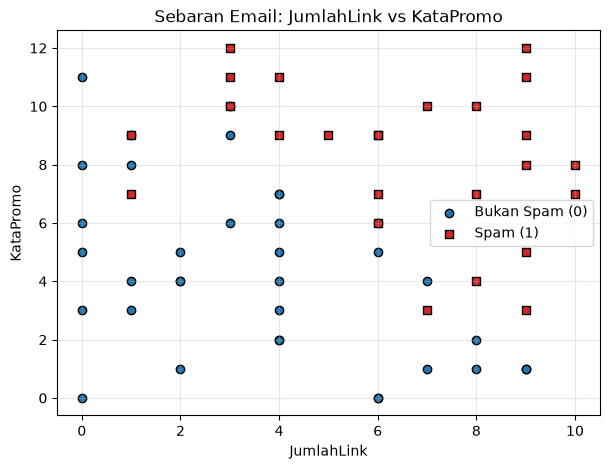

In [11]:
# Jawaban B1
df_email = pd.read_csv("Email_Data.csv")
display(df_email.head())
print("Jumlah baris data:", len(df_email))
print("Jumlah email Bukan Spam (0):", int((df_email["Spam"] == 0).sum()))
print("Jumlah email Spam (1)      :", int((df_email["Spam"] == 1).sum()))

X_e = df_email[["JumlahLink", "KataPromo"]].values.astype(float)
y_e = df_email["Spam"].values
print("Shape X_e:", X_e.shape, "| Shape y_e:", y_e.shape)

plt.figure(figsize=(7, 5))
plt.scatter(X_e[y_e == 0, 0], X_e[y_e == 0, 1], color="tab:blue", edgecolor="k", label="Bukan Spam (0)")
plt.scatter(X_e[y_e == 1, 0], X_e[y_e == 1, 1], color="tab:red", edgecolor="k", marker="s", label="Spam (1)")
plt.title("Sebaran Email: JumlahLink vs KataPromo")
plt.xlabel("JumlahLink")
plt.ylabel("KataPromo")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Jawaban B1 (pengamatan):** Dari 60 email terdapat 35 Bukan Spam dan 25 Spam. Email spam banyak berkumpul di kanan atas (banyak link dan banyak kata promo), sedangkan bukan spam di kiri bawah. Kedua kelas tidak terpisah sempurna karena ada titik yang bercampur di tengah, tetapi pola pemisahan dengan garis lurus terlihat.

## Soal B2 – Split Data & Training

1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:

$$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$

4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Xe_train: (45, 2) | Xe_test: (15, 2)
Intercept (b)  : -9.2040
Koefisien m1   : 0.8013  (JumlahLink)
Koefisien m2   : 0.8248  (KataPromo)
Persamaan      : P(Spam) = sigmoid(-9.2040 + 0.8013*JumlahLink + 0.8248*KataPromo)
Log loss pada iterasi 1, 100, 1000, 5000, 10000: [0.6931, 0.5518, 0.3397, 0.3024, 0.3009]


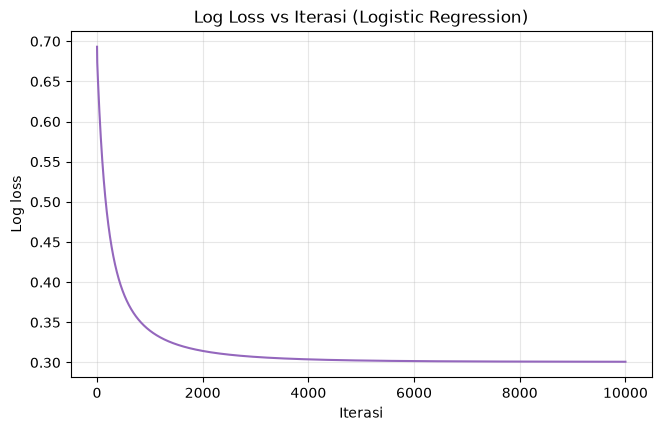

In [12]:
# Jawaban B2
Xe_train, Xe_test, ye_train, ye_test = train_test_split(X_e, y_e, test_size=0.25, random_state=RANDOM_STATE)
print("Xe_train:", Xe_train.shape, "| Xe_test:", Xe_test.shape)

log_model = LogisticRegression(learning_rate=0.1, n_iterations=10000)
log_model.fit(Xe_train, ye_train)

b_log = log_model.intercept_
m1_log, m2_log = log_model.coef_
print(f"Intercept (b)  : {b_log:.4f}")
print(f"Koefisien m1   : {m1_log:.4f}  (JumlahLink)")
print(f"Koefisien m2   : {m2_log:.4f}  (KataPromo)")
print(f"Persamaan      : P(Spam) = sigmoid({b_log:.4f} + {m1_log:.4f}*JumlahLink + {m2_log:.4f}*KataPromo)")

hist = log_model.loss_history_
print("Log loss pada iterasi 1, 100, 1000, 5000, 10000:", [round(float(hist[i - 1]), 4) for i in (1, 100, 1000, 5000, 10000)])

plt.figure(figsize=(7.5, 4.5))
plt.plot(range(1, len(hist) + 1), hist, color="tab:purple")
plt.title("Log Loss vs Iterasi (Logistic Regression)")
plt.xlabel("Iterasi")
plt.ylabel("Log loss")
plt.grid(alpha=0.3)
plt.show()

**Jawaban B2 (analisis):**

Persamaan model: $P(\text{Spam}) = \sigma(-9{,}2040 + 0{,}8013\cdot\text{JumlahLink} + 0{,}8248\cdot\text{KataPromo})$.

Kedua koefisien positif, artinya makin banyak link atau makin banyak kata promo, peluang spam makin besar. Pengaruh keduanya hampir sama kuat (0,80 dan 0,82).

Log loss turun tajam dari 0,6931 (iterasi 1) ke 0,3397 (iterasi 1000), lalu melandai ke 0,3024 (iterasi 5000) dan 0,3009 (iterasi 10000). Jadi loss **sudah turun dan stabil**; penurunan dari iterasi 5000 ke 10000 hanya sekitar 0,0015, meskipun secara teknis masih sedikit menurun.

## Soal B3 – Evaluasi Model

Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$Precision = \frac{TP}{TP + FP} \qquad Recall = \frac{TP}{TP + FN} \qquad F1 = 2\cdot\frac{Precision \cdot Recall}{Precision + Recall}$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [13]:
# Jawaban B3
def precision_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p, r = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

pred_e_test = log_model.predict(Xe_test)               # threshold default 0.5
cm = confusion_matrix(ye_test, pred_e_test)

print("Accuracy (testing):", round(accuracy_score(ye_test, pred_e_test), 4))
print("Precision         :", round(precision_score(ye_test, pred_e_test), 4))
print("Recall            :", round(recall_score(ye_test, pred_e_test), 4))
print("F1-score          :", round(f1_score(ye_test, pred_e_test), 4))
print("Accuracy (training):", round(accuracy_score(ye_train, log_model.predict(Xe_train)), 4))
print("\nConfusion matrix (baris = aktual, kolom = prediksi):")
display(pd.DataFrame(cm, index=["Aktual Bukan Spam", "Aktual Spam"], columns=["Prediksi Bukan Spam", "Prediksi Spam"]))
print(f"TN={cm[0,0]}  FP={cm[0,1]}  FN={cm[1,0]}  TP={cm[1,1]}")

Accuracy (testing): 0.9333
Precision         : 0.8333
Recall            : 1.0
F1-score          : 0.9091
Accuracy (training): 0.8889

Confusion matrix (baris = aktual, kolom = prediksi):


,Prediksi Bukan Spam,Prediksi Spam
Aktual Bukan Spam,9,1
Aktual Spam,0,5


TN=9  FP=1  FN=0  TP=5


**Jawaban B3 (analisis):**

Pada data testing (15 email): accuracy = 0,933, precision = 0,833, recall = 1,00, dan F1 = 0,909. Confusion matrix: TN = 9, FP = 1, FN = 0, TP = 5. (Accuracy training 0,889, jadi justru sedikit lebih rendah daripada testing.)

- **FP (false positive)**: email yang sebenarnya **bukan spam** tetapi dianggap spam, sehingga terlempar ke folder spam.
- **FN (false negative)**: email yang sebenarnya **spam** tetapi lolos masuk ke inbox.

Menurut saya **FP lebih merugikan**. Email penting seperti undangan wawancara, tagihan, atau info kuliah bisa tidak terbaca karena masuk folder spam. FN hanya membuat inbox kotor dan pengguna masih bisa menghapusnya sendiri, jadi kerugiannya lebih kecil.

## Soal B4 – Decision Boundary

1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):

$$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$

2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: x2 = 11.1589 + (-0.9715) * x1
(x1 = JumlahLink, x2 = KataPromo)


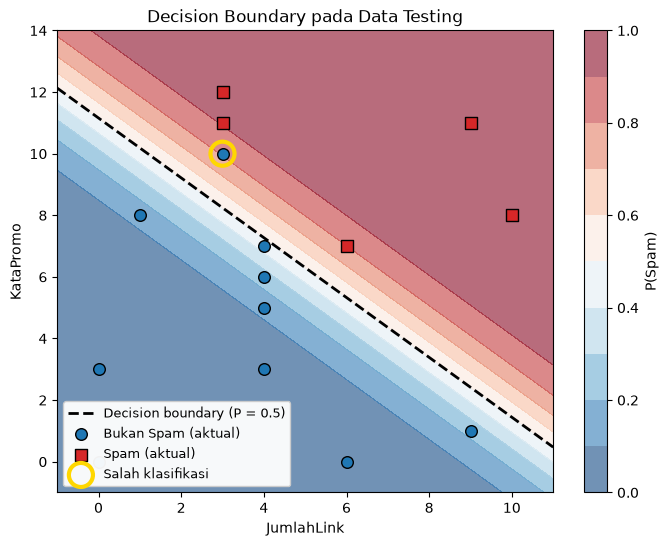

,JumlahLink,KataPromo,Aktual,Prediksi,P(Spam)
0,3.0,10.0,0,1,0.81


In [14]:
# Jawaban B4
# 1. Persamaan decision boundary
intercept_garis = -b_log / m2_log
slope_garis = -m1_log / m2_log
print(f"Decision boundary: x2 = {intercept_garis:.4f} + ({slope_garis:.4f}) * x1")
print("(x1 = JumlahLink, x2 = KataPromo)")

# 2. Background probabilitas dengan contourf
x1_min, x1_max = 0 - 1, 11
x2_min, x2_max = 0 - 1, 14
g1, g2 = np.meshgrid(np.linspace(x1_min, x1_max, 300), np.linspace(x2_min, x2_max, 300))
prob_grid = log_model.predict_proba(np.c_[g1.ravel(), g2.ravel()]).reshape(g1.shape)

plt.figure(figsize=(8, 6))
cs = plt.contourf(g1, g2, prob_grid, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.6)
plt.colorbar(cs, label="P(Spam)")

x_line = np.linspace(x1_min, x1_max, 100)
plt.plot(x_line, intercept_garis + slope_garis * x_line, "k--", linewidth=2, label="Decision boundary (P = 0.5)")

# titik data testing
plt.scatter(Xe_test[ye_test == 0, 0], Xe_test[ye_test == 0, 1], color="tab:blue", edgecolor="k", s=70, label="Bukan Spam (aktual)")
plt.scatter(Xe_test[ye_test == 1, 0], Xe_test[ye_test == 1, 1], color="tab:red", edgecolor="k", marker="s", s=70, label="Spam (aktual)")

# 3. Tandai data testing yang salah diklasifikasikan
salah = pred_e_test != ye_test
plt.scatter(Xe_test[salah, 0], Xe_test[salah, 1], facecolors="none", edgecolors="gold", s=300, linewidths=3, label="Salah klasifikasi")

plt.xlim(x1_min, x1_max); plt.ylim(x2_min, x2_max)
plt.title("Decision Boundary pada Data Testing")
plt.xlabel("JumlahLink")
plt.ylabel("KataPromo")
plt.legend(loc="lower left", fontsize=9, framealpha=0.95)
plt.show()

# daftar data yang salah
prob_test = log_model.predict_proba(Xe_test)
tabel_salah = pd.DataFrame({
    "JumlahLink": Xe_test[salah, 0], "KataPromo": Xe_test[salah, 1],
    "Aktual": ye_test[salah], "Prediksi": pred_e_test[salah], "P(Spam)": prob_test[salah].round(3)})
display(tabel_salah)

**Jawaban B4 (analisis):**

Persamaan decision boundary: $x_2 = 11{,}1589 - 0{,}9715\,x_1$ (dengan $x_1$ = JumlahLink dan $x_2$ = KataPromo). Titik di atas atau di kanan garis diprediksi **Spam**, titik di bawah atau di kiri garis diprediksi **Bukan Spam**.

Hanya ada **1 email testing yang salah** (dilingkari kuning): (JumlahLink = 3, KataPromo = 10), aslinya Bukan Spam, tetapi diprediksi Spam (P = 0,81). Ini **FP**. Titik ini berada tepat di sisi spam dari garis karena kata promonya banyak, padahal jumlah linknya sedikit. Karena garis pemisah hanya bisa lurus dan kedua kelas saling bercampur di tengah, kesalahan seperti ini sulit dihindari. Tidak ada FN: semua 5 email spam di data testing terdeteksi.

## Soal B5 – Eksperimen Threshold

Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [15]:
# Jawaban B5
proba_test = log_model.predict_proba(Xe_test)

baris = []
for t in [0.3, 0.5, 0.7]:
    pred_t = (proba_test >= t).astype(int)
    cm_t = confusion_matrix(ye_test, pred_t)
    baris.append({"Threshold": t, "TN": cm_t[0, 0], "FP": cm_t[0, 1], "FN": cm_t[1, 0], "TP": cm_t[1, 1],
                  "Precision": precision_score(ye_test, pred_t), "Recall": recall_score(ye_test, pred_t)})
tabel_threshold = pd.DataFrame(baris).round(4)
display(tabel_threshold)

,Threshold,TN,FP,FN,TP,Precision,Recall
0,0.3,8,2,0,5,0.7143,1.0
1,0.5,9,1,0,5,0.8333,1.0
2,0.7,9,1,0,5,0.8333,1.0


**Jawaban B5 (analisis):**

Hasil tabel: threshold 0,3 memberi FP = 2, FN = 0 (precision 0,714; recall 1,00). Threshold 0,5 dan 0,7 memberi hasil yang sama: FP = 1, FN = 0 (precision 0,833; recall 1,00).

**Pengaruh threshold:** menaikkan threshold membuat model lebih hati-hati menyebut sebuah email spam, sehingga FP berkurang dan **precision naik**, tetapi spam yang lolos bisa bertambah sehingga **recall turun**. Menurunkan threshold berefek sebaliknya: model lebih mudah menyebut spam, recall bisa naik, tetapi precision turun. Pada data ini, menurunkan ke 0,3 hanya menambah FP dari 1 menjadi 2 (precision turun) tanpa menambah spam yang tertangkap, karena recall sudah 1,00 (semua spam testing punya probabilitas di atas 0,79). Antara 0,5 dan 0,7 tidak ada perbedaan di data testing ini, karena tidak ada satu pun email testing yang probabilitasnya berada di antara 0,5 dan 0,7.

**Threshold pilihan saya: 0,7.** Karena menurut jawaban B3 FP (email penting masuk spam) lebih merugikan, saya memilih threshold yang lebih ketat agar lebih sedikit email asli yang terbuang. Pada data testing 0,7 memberi hasil sama dengan 0,5, jadi tidak ada recall yang dikorbankan, tetapi dengan data testing yang hanya 15 email pilihan ini lebih berdasarkan alasan biaya kesalahan daripada selisih angka.

## Soal B6 – Prediksi Email Baru

Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [16]:
# Jawaban B6
THRESHOLD = 0.7    # threshold pilihan dari Soal B5
email_baru = np.array([[1, 2], [5, 6], [9, 10], [2, 11]], dtype=float)
proba_baru = log_model.predict_proba(email_baru)
kelas_baru = (proba_baru >= THRESHOLD).astype(int)

hasil_b6 = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": email_baru[:, 0].astype(int),
    "KataPromo": email_baru[:, 1].astype(int),
    "P(Spam)": proba_baru.round(4),
    "Kelas": np.where(kelas_baru == 1, "Spam", "Bukan Spam"),
})
display(hasil_b6)

,Email,JumlahLink,KataPromo,P(Spam),Kelas
0,E1,1,2,0.0012,Bukan Spam
1,E2,5,6,0.4382,Bukan Spam
2,E3,9,10,0.9981,Spam
3,E4,2,11,0.8133,Spam


**Jawaban B6 (analisis):** Dengan threshold 0,7: **E1** (P = 0,0012) Bukan Spam; **E2** (P = 0,4382) Bukan Spam; **E3** (P = 0,9981) Spam; **E4** (P = 0,8133) Spam. E3 jelas spam karena link dan kata promonya banyak. E4 hanya punya 2 link tetapi 11 kata promo, dan probabilitasnya (0,813) hanya cukup di atas threshold 0,7, jadi ini kasus yang paling tidak pasti bersama E2 (P = 0,438, yang berada di tengah-tengah).

---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression termasuk klasifikasi karena keluaran akhirnya adalah kelas (misalnya Spam atau Bukan Spam), bukan angka bebas. Kata "regression" ada karena di dalamnya masih ada persamaan linear $b + m_1x_1 + m_2x_2$ seperti regresi linear. Peran **sigmoid** adalah mengubah hasil persamaan itu (yang bisa bernilai berapa saja) menjadi angka antara 0 dan 1 sehingga bisa dibaca sebagai probabilitas. Lalu probabilitas dibandingkan dengan threshold untuk memutuskan kelasnya. Contohnya pada email E3 di tugas ini, hasil persamaannya besar sehingga sigmoid mengubahnya menjadi P(Spam) = 0,998.

**Jawaban C2:** **Normal equation** menghitung parameter terbaik langsung dalam satu kali rumus (dengan invers matriks), sedangkan **gradient descent** memulai dari tebakan awal lalu memperbaiki parameter sedikit demi sedikit secara berulang mengikuti arah turunnya loss. Normal equation tidak perlu learning rate dan iterasi, tetapi menjadi berat kalau fitur sangat banyak karena harus membalik matriks besar. Gradient descent lebih baik dipakai saat data atau jumlah fiturnya sangat besar, dan juga untuk model yang tidak punya rumus langsung seperti Logistic Regression. Di tugas ini, gradient descent dengan learning rate 0,02 menghasilkan b = 28,15 dan m = 9,29, sama dengan normal equation.

**Jawaban C3:** Model sudah "melihat" data training saat belajar, jadi nilainya di sana bisa bagus hanya karena model menghafal, seperti siswa yang diuji dengan soal latihan yang sama. Data testing adalah data baru yang belum pernah dilihat, sehingga menunjukkan kemampuan model sebenarnya pada data nyata. **Overfitting** adalah kondisi model terlalu menyesuaikan diri dengan data training (termasuk noise-nya) sehingga bagus di training tetapi buruk di data baru. Pada Logistic Regression di tugas ini, akurasi training 0,889 sedangkan testing 0,933; testing justru tidak lebih buruk dari training, jadi tidak ada tanda overfitting, tetapi karena data testing hanya 15 email kesimpulan ini belum pasti.

**Jawaban C4:** Linear Regression menghasilkan angka kontinu (misalnya penjualan), sehingga wajar mengukur kesalahan dengan jarak antara angka prediksi dan angka asli. MSE melakukannya dengan mengkuadratkan selisihnya, dan bentuknya mulus sehingga mudah diturunkan untuk gradient descent. Logistic Regression menghasilkan probabilitas 0 sampai 1 untuk label 0 atau 1, sehingga lebih cocok memakai **log loss** yang memberi hukuman sangat besar jika model yakin tetapi salah (misal memprediksi 0,01 padahal sebenarnya spam). Jika MSE dipakai bersama sigmoid, permukaan loss-nya jadi tidak mulus dan pembelajaran bisa lambat, sedangkan log loss membuat gradient descent lebih stabil.

**Jawaban C5:** Pembagian data training dan testing dilakukan secara acak, dan hasil acaknya ditentukan oleh `random_state`. Karena `random_state` setiap mahasiswa berbeda (dari NIM), data yang dipakai untuk melatih dan menguji juga berbeda, sehingga koefisien dan akurasinya ikut berbeda. Efeknya besar karena datanya sedikit (40 dan 60 baris). Contohnya, data testing email saya hanya 15, jadi satu email yang salah saja sudah mengubah akurasi sekitar 6,7%.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi sendiri. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.

In [17]:
# Bonus: perbandingan dengan scikit-learn (satu-satunya bagian yang boleh memakai scikit-learn)
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

# --- Linear Regression ---
sk_lin = SkLinearRegression().fit(X_train, y_train)
tabel_lin = pd.DataFrame({
    "Intercept (b)": [b_ne, sk_lin.intercept_],
    "Koefisien (m)": [m_ne, sk_lin.coef_[0]],
    "R2 testing": [r2_score(y_test, pred_test), r2_score(y_test, sk_lin.predict(X_test))],
}, index=["Implementasi sendiri", "scikit-learn"]).round(6)
display(tabel_lin)

# --- Logistic Regression ---
sk_log_default = SkLogisticRegression().fit(Xe_train, ye_train)                       # penalty='l2', C=1.0
sk_log_nopen = SkLogisticRegression(C=1e10, max_iter=100000).fit(Xe_train, ye_train)  # regularisasi hampir mati

def log_loss_train(p):
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return -np.mean(ye_train * np.log(p) + (1 - ye_train) * np.log(1 - p))

baris = []
for nama, mdl in [("Implementasi sendiri (GD)", log_model),
                  ("sklearn default (C=1.0, L2)", sk_log_default),
                  ("sklearn C=1e10 (tanpa regularisasi)", sk_log_nopen)]:
    if hasattr(mdl, "predict_proba") and nama.startswith("Impl"):
        p_tr, pred = mdl.predict_proba(Xe_train), mdl.predict(Xe_test)
        b0, m0 = mdl.intercept_, mdl.coef_
    else:
        p_tr, pred = mdl.predict_proba(Xe_train)[:, 1], mdl.predict(Xe_test)
        b0, m0 = mdl.intercept_[0], mdl.coef_[0]
    baris.append({"Model": nama, "b": b0, "m1 (JumlahLink)": m0[0], "m2 (KataPromo)": m0[1],
                  "Log loss train": log_loss_train(p_tr), "Akurasi testing": accuracy_score(ye_test, pred)})
display(pd.DataFrame(baris).round(4))

,Intercept (b),Koefisien (m),R2 testing
Implementasi sendiri,28.148126,9.285561,0.919598
scikit-learn,28.148126,9.285561,0.919598


,Model,b,m1 (JumlahLink),m2 (KataPromo),Log loss train,Akurasi testing
0,Implementasi sendiri (GD),-9.2040,0.8013,0.8248,0.3009,0.9333
1,"sklearn default (C=1.0, L2)",-8.4815,0.7342,0.7605,0.3022,0.9333
2,sklearn C=1e10 (tanpa regularisasi),-9.4943,0.8270,0.8500,0.3008,0.9333


**Jawaban Bonus (analisis):**

- **Linear Regression:** hasilnya **identik** (b = 28,1481 dan m = 9,2856, R² testing sama = 0,9196) karena keduanya menyelesaikan masalah kuadrat terkecil yang sama secara eksak.
- **Logistic Regression:** koefisien **berbeda**. Implementasi saya: b = −9,20, m₁ = 0,80, m₂ = 0,82. scikit-learn default: b = −8,48, m₁ = 0,73, m₂ = 0,76, yaitu lebih kecil. Penyebabnya, `LogisticRegression` scikit-learn secara default memakai **regularisasi L2** (`penalty='l2'`, `C=1.0`) yang sengaja mengecilkan koefisien, sedangkan implementasi saya tidak memakai penalti. Selain itu, scikit-learn memakai solver `lbfgs`, bukan gradient descent biasa.
- Jika regularisasi hampir dimatikan (`C=1e10`), koefisien scikit-learn justru **sedikit lebih besar** daripada punya saya (b = −9,49, m₁ = 0,83, m₂ = 0,85) dengan log loss training yang hampir sama (0,3008 vs 0,3009). Ini menunjukkan gradient descent saya sudah hampir konvergen setelah 10.000 iterasi, tetapi belum benar-benar sampai (loss masih menurun sangat pelan), sejalan dengan analisis B2.
- Walaupun koefisiennya berbeda, **akurasi testing sama (0,933)** untuk ketiga model, karena pada data ini arah garis pemisahnya mirip sehingga hanya sedikit titik yang bergeser sisi.